In [1]:
from scipy import stats

# Binomial: peluang tepat 3 sukses dari 10 percobaan, p = 0.5
print(stats.binom.pmf(3, n=10, p=0.5))      # 0.1171875

# Normal: P(Z <= 1.96)
print(stats.norm.cdf(1.96))                  # ~0.975

# Nilai z untuk peluang kumulatif 97.5%
print(stats.norm.ppf(0.975))                 # ~1.96

# Generate 5 sampel acak dari Poisson (lambda = 3)
print(stats.poisson.rvs(mu=3, size=5))

0.1171875
0.9750021048517795
1.959963984540054
[2 9 4 3 2]


In [2]:
from statistics import NormalDist, mean, stdev

nd = NormalDist(mu=50, sigma=10)
print(nd.cdf(60))        # P(X <= 60)
print(nd.pdf(50))        # kepadatan di x = 50
print(nd.inv_cdf(0.95))  # nilai x untuk persentil 95

print(mean([2, 4, 6]), stdev([2, 4, 6]))

0.8413447460685429
0.03989422804014327
66.44853626951472
4 2.0


In [3]:
from sympy.stats import Die, Normal, P, E, variance

X = Die('X', 6)          # dadu 6 sisi
print(P(X > 4))          # 1/3
print(E(X))              # 7/2
print(variance(X))       # 35/12

Z = Normal('Z', 0, 1)
print(P(Z < 0))          # 1/2

1/3
7/2
35/12
1/2


In [4]:
import math, itertools, random

print(math.comb(5, 2))   # kombinasi C(5,2) = 10
print(math.perm(5, 2))   # permutasi P(5,2) = 20

# Ruang sampel 2 koin
print(list(itertools.product(['H', 'T'], repeat=2)))

# Simulasi: peluang jumlah 2 dadu = 7 (teori: 1/6)
n = 100_000
hit = sum(random.randint(1,6) + random.randint(1,6) == 7 for _ in range(n))
print(hit / n)           # ~0.1667

10
20
[('H', 'H'), ('H', 'T'), ('T', 'H'), ('T', 'T')]
0.16766


In [5]:
import numpy as np

rng = np.random.default_rng(42)           # seed supaya hasil konsisten
data = rng.binomial(n=10, p=0.5, size=1000)
print(data.mean(), data.var())            # mendekati 5 dan 2.5

print(rng.normal(loc=0, scale=1, size=5))

4.97 2.5751
[-0.74219209  0.92435776  0.03461187 -0.28279575 -0.10618193]


0.5


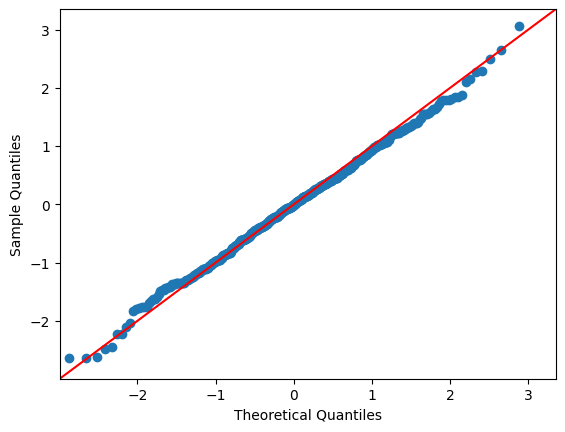

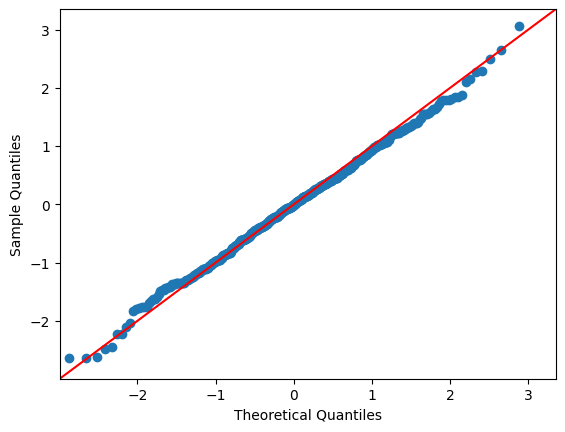

In [6]:
import numpy as np
import statsmodels.api as sm
from statsmodels.distributions.empirical_distribution import ECDF

data = np.random.normal(0, 1, 500)

ecdf = ECDF(data)
print(ecdf(0))                    # estimasi P(X <= 0), ~0.5

sm.qqplot(data, line='45')        # Q-Q plot cek normalitas

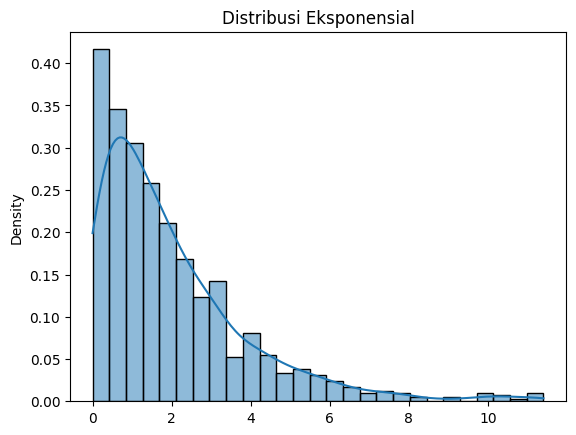

In [7]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

data = np.random.exponential(scale=2, size=1000)
sns.histplot(data, kde=True, stat="density")
plt.title("Distribusi Eksponensial")
plt.show()

In [10]:
pip install distfit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [distfit]


[02-11-2026 16:15:17] [distfit.distfit] [INFO] fit
[02-11-2026 16:15:17] [distfit.distfit] [INFO] transform
[02-11-2026 16:15:17] [distfit.distfit] [INFO] [norm      ] [0.00 sec] [RSS: 0.0159923] [loc=4.050 scale=2.871]
[02-11-2026 16:15:17] [distfit.distfit] [INFO] [expon     ] [0.00 sec] [RSS: 0.0296428] [loc=0.048 scale=4.002]
[02-11-2026 16:15:17] [distfit.distfit] [INFO] [pareto    ] [0.00 sec] [RSS: 0.0296428] [loc=-1073741823.952 scale=1073741824.000]
[02-11-2026 16:15:17] [distfit.distfit] [INFO] [dweibull  ] [0.02 sec] [RSS: 0.0109018] [loc=3.615 scale=2.268]
[02-11-2026 16:15:17] [distfit.distfit] [INFO] [t         ] [0.08 sec] [RSS: 0.012161] [loc=3.668 scale=2.231]
[02-11-2026 16:15:17] [distfit.distfit] [INFO] [genextreme] [0.09 sec] [RSS: 0.00347367] [loc=2.662 scale=1.944]
[02-11-2026 16:15:17] [distfit.distfit] [INFO] [gamma     ] [0.01 sec] [RSS: 0.00152632] [loc=-0.064 scale=2.058]
[02-11-2026 16:15:17] [distfit.distfit] [INFO] [lognorm   ] [0.00 sec] [RSS: 0.0027885]

         name     score
0       gamma  0.001526
1        beta  0.001934
2     lognorm  0.002789
3  genextreme  0.003474
4    dweibull  0.010902


(<Figure size 2000x1500 with 1 Axes>,
 <Axes: title={'center': '\ngamma(a=1.99917, loc=-0.0639656, scale=2.05766)'}, xlabel='Density values', ylabel='Frequency'>)

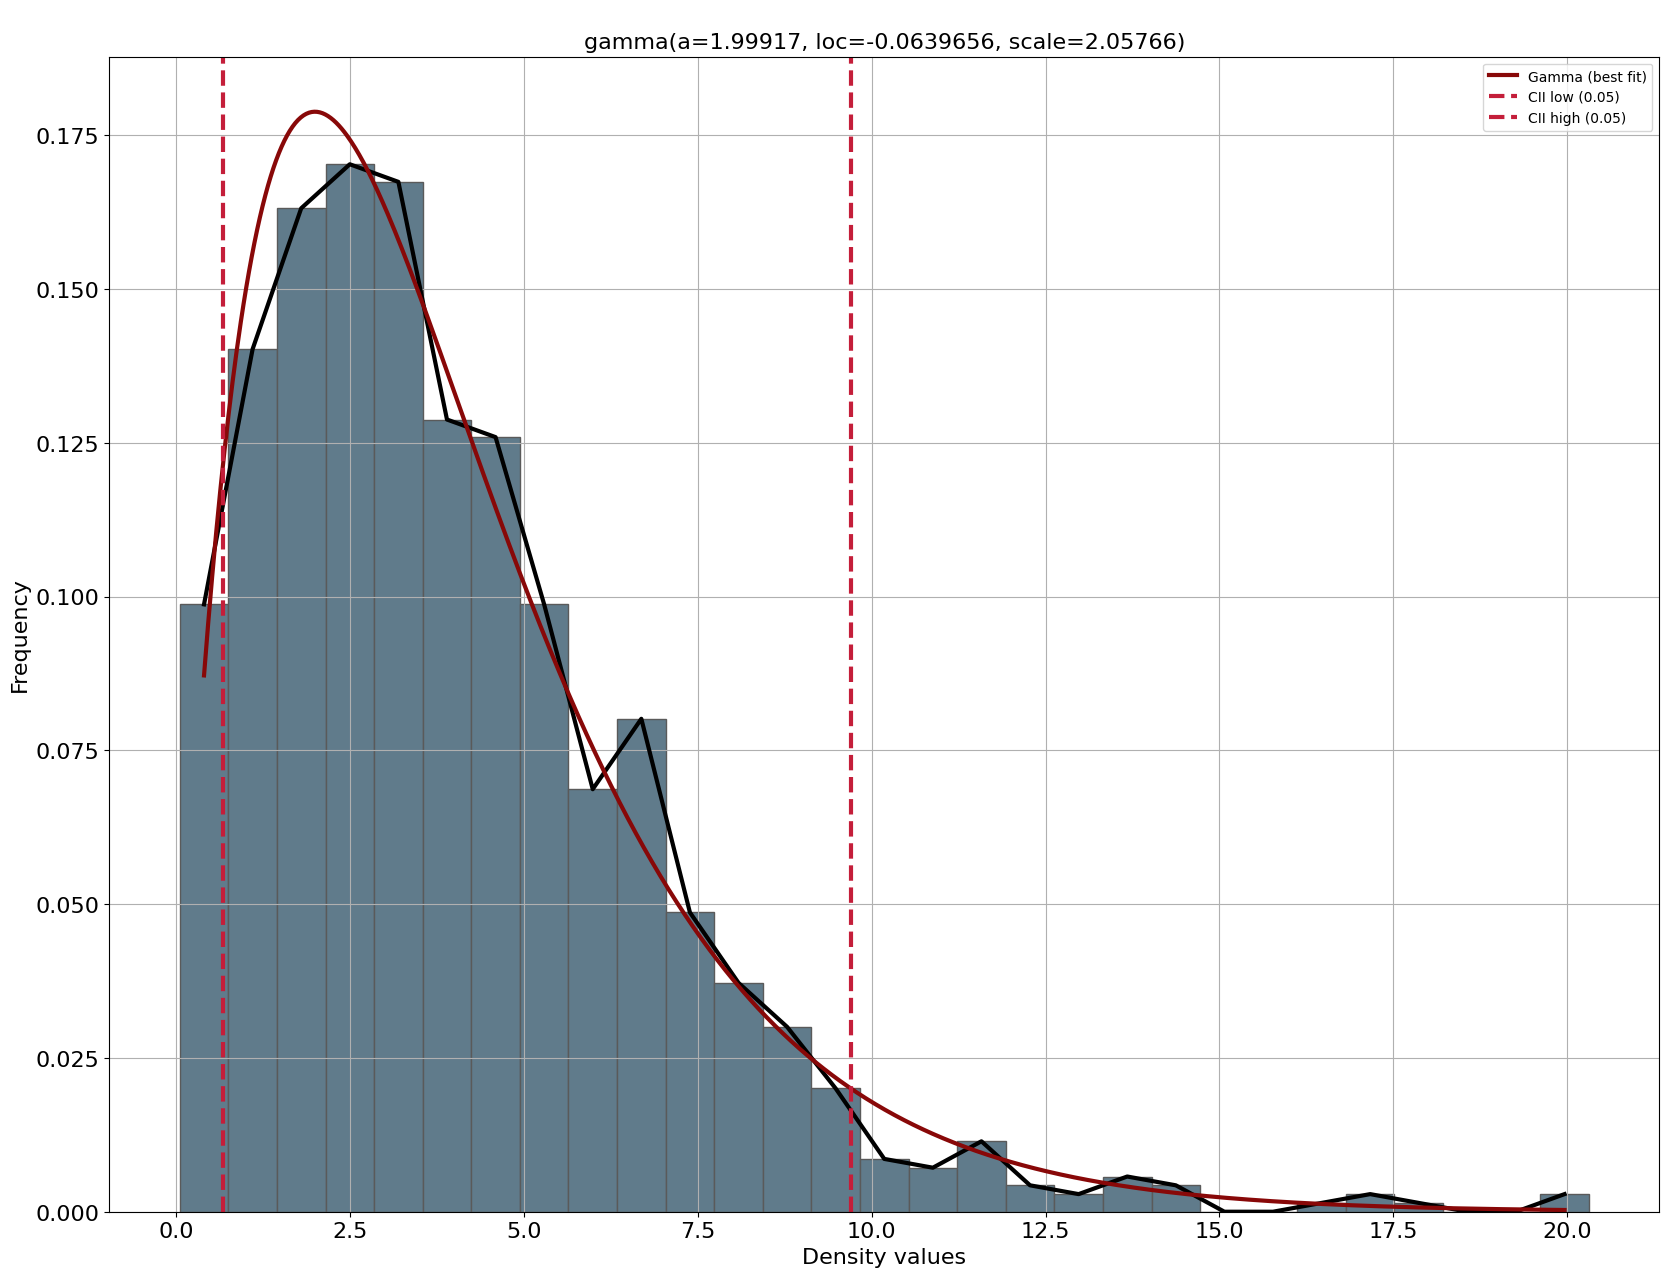

In [11]:
import numpy as np
from distfit import distfit

data = np.random.gamma(shape=2, scale=2, size=1000)

dist = distfit()
dist.fit_transform(data)
print(dist.summary[['name', 'score']].head())  # ranking distribusi terbaik
dist.plot()

In [12]:
import pymc as pm

# Ambil 5 sampel dari distribusi Normal(0,1)
print(pm.draw(pm.Normal.dist(mu=0, sigma=1), draws=5))

# Estimasi mean dari data (inferensi Bayesian)
data = [4.8, 5.1, 5.3, 4.9, 5.0]
with pm.Model():
    mu = pm.Normal("mu", mu=0, sigma=10)
    pm.Normal("obs", mu=mu, sigma=1, observed=data)
    idata = pm.sample(1000, progressbar=False)

[-0.67675518 -0.60436333 -0.53553549  0.23273309 -0.65699195]


In [13]:
import tensorflow_probability as tfp
tfd = tfp.distributions

dist = tfd.Normal(loc=0., scale=1.)
print(dist.prob(0.))      # pdf di x = 0
print(dist.cdf(1.96))     # cdf
print(dist.sample(5))     # 5 sampel acak

tf.Tensor(0.3989423, shape=(), dtype=float32)
tf.Tensor(0.9750021, shape=(), dtype=float32)
tf.Tensor([ 0.5249138  -0.6630106   0.08071399  1.6645948  -1.1221554 ], shape=(5,), dtype=float32)


Perhitungan Probabilitas

In [14]:
from math import comb
from scipy import stats

n, p = 10, 0.25

# Manual (rumus binomial)
manual_3 = comb(n, 3) * p**3 * (1-p)**(n-3)
manual_ge6 = sum(comb(n, k) * p**k * (1-p)**(n-k) for k in range(6, n+1))

# SciPy
scipy_3 = stats.binom.pmf(3, n, p)
scipy_ge6 = stats.binom.sf(5, n, p)   # survival function: P(X > 5)

print(f"P(X = 3)  manual = {manual_3:.5f} | scipy = {scipy_3:.5f}")
print(f"P(X >= 6) manual = {manual_ge6:.5f} | scipy = {scipy_ge6:.5f}")
print(f"E[X] = {stats.binom.mean(n, p)}, Var(X) = {stats.binom.var(n, p)}")

print("\nk  P(X=k)")
for k in range(n+1):
    print(f"{k:<2} {stats.binom.pmf(k, n, p):.5f}")

P(X = 3)  manual = 0.25028 | scipy = 0.25028
P(X >= 6) manual = 0.01973 | scipy = 0.01973
E[X] = 2.5, Var(X) = 1.875

k  P(X=k)
0  0.05631
1  0.18771
2  0.28157
3  0.25028
4  0.14600
5  0.05840
6  0.01622
7  0.00309
8  0.00039
9  0.00003
10 0.00000


In [15]:
import pandas as pd

df = pd.DataFrame({'Lulus': [45, 10], 'Tidak Lulus': [15, 30]},
                  index=['Rajin', 'Tidak Rajin'])

total = df.values.sum()
p_L   = df['Lulus'].sum() / total
p_R   = df.loc['Rajin'].sum() / total
p_LR  = df.loc['Rajin', 'Lulus'] / total

p_L_given_R = p_LR / p_R
p_R_given_L = p_LR / p_L

print(df, "\n")
print(f"P(L)     = {p_L:.4f}")
print(f"P(R)     = {p_R:.4f}")
print(f"P(L ∩ R) = {p_LR:.4f}")
print(f"P(L | R) = {p_L_given_R:.4f}")
print(f"P(R | L) = {p_R_given_L:.4f}")
print(f"P(L|Tidak Rajin) = {df.loc['Tidak Rajin','Lulus']/df.loc['Tidak Rajin'].sum():.4f}")

print(f"\nP(L)*P(R) = {p_L*p_R:.4f}  vs  P(L∩R) = {p_LR:.4f}")
print("Independen?", abs(p_L*p_R - p_LR) < 1e-9)

             Lulus  Tidak Lulus
Rajin           45           15
Tidak Rajin     10           30 

P(L)     = 0.5500
P(R)     = 0.6000
P(L ∩ R) = 0.4500
P(L | R) = 0.7500
P(R | L) = 0.8182
P(L|Tidak Rajin) = 0.2500

P(L)*P(R) = 0.3300  vs  P(L∩R) = 0.4500
Independen? False


In [16]:
from sympy import Rational
import numpy as np

# --- 1. Rumus Bayes langsung ---
p_spam, p_ham = 0.30, 0.70
p_k_spam, p_k_ham = 0.60, 0.05

p_k = p_k_spam*p_spam + p_k_ham*p_ham
post = p_k_spam*p_spam / p_k

print(f"P(gratis)        = {p_k:.4f}")
print(f"P(spam | gratis) = {post:.4f}")
print(f"P(ham  | gratis) = {1-post:.4f}")

# --- 2. Eksak pakai SymPy ---
S, H = Rational(3, 10), Rational(7, 10)
r = (Rational(6, 10)*S) / (Rational(6, 10)*S + Rational(5, 100)*H)
print("Simbolik:", r, "=", float(r))

# --- 3. Verifikasi simulasi ---
rng = np.random.default_rng(1)
N = 1_000_000
spam = rng.random(N) < 0.30
kata = np.where(spam, rng.random(N) < 0.60, rng.random(N) < 0.05)
print(f"Simulasi P(spam|gratis) = {spam[kata].mean():.4f}")

P(gratis)        = 0.2150
P(spam | gratis) = 0.8372
P(ham  | gratis) = 0.1628
Simbolik: 36/43 = 0.8372093023255814
Simulasi P(spam|gratis) = 0.8368


In [17]:
import itertools
import numpy as np

pA, pB = 0.05, 0.03

# --- Rumus ---
p_both        = pA * pB
p_union       = pA + pB - p_both
p_exactly_one = pA*(1-pB) + (1-pA)*pB
p_none        = (1-pA) * (1-pB)

print(f"P(A∩B)       = {p_both:.4f}")
print(f"P(A∪B)       = {p_union:.4f}")
print(f"P(tepat satu)= {p_exactly_one:.4f}")
print(f"P(tidak ada) = {p_none:.4f}")
print(f"Cek total    = {p_both + p_exactly_one + p_none:.4f}")

# --- Enumerasi semua kombinasi (0 = normal, 1 = down) ---
tot = 0
for sa, sb in itertools.product([0, 1], repeat=2):
    pr = (pA if sa else 1-pA) * (pB if sb else 1-pB)
    if sa or sb:
        tot += pr
print(f"Enumerasi P(A∪B) = {tot:.4f}")

# --- Simulasi ---
rng = np.random.default_rng(7)
N = 1_000_000
A = rng.random(N) < pA
B = rng.random(N) < pB
print(f"Simulasi P(A∪B) = {(A | B).mean():.4f}")

P(A∩B)       = 0.0015
P(A∪B)       = 0.0785
P(tepat satu)= 0.0770
P(tidak ada) = 0.9215
Cek total    = 1.0000
Enumerasi P(A∪B) = 0.0785
Simulasi P(A∪B) = 0.0784


In [18]:
import numpy as np

def exact(n, hari=365):
    q = 1.0
    for i in range(n):
        q *= (hari - i) / hari
    return 1 - q

def simulasi(n, trials=100_000, hari=365, seed=42):
    rng = np.random.default_rng(seed)
    data = rng.integers(0, hari, size=(trials, n))   # tiap baris = 1 kelas
    s = np.sort(data, axis=1)
    return (s[:, 1:] == s[:, :-1]).any(axis=1).mean()  # ada duplikat?

print(f"{'n':>4} {'Eksak':>10} {'Monte Carlo':>12} {'Selisih':>10}")
for n in (10, 23, 30, 50):
    e, m = exact(n), simulasi(n)
    print(f"{n:>4} {e:>10.4f} {m:>12.4f} {abs(e-m):>10.4f}")

print("\nKonvergensi (n = 23):")
for t in (100, 1_000, 10_000, 100_000, 1_000_000):
    print(f"trials = {t:>9,} -> {simulasi(23, t):.4f}")

   n      Eksak  Monte Carlo    Selisih
  10     0.1169       0.1179     0.0009
  23     0.5073       0.5080     0.0007
  30     0.7063       0.7075     0.0012
  50     0.9704       0.9698     0.0005

Konvergensi (n = 23):
trials =       100 -> 0.4700
trials =     1,000 -> 0.4930
trials =    10,000 -> 0.4991
trials =   100,000 -> 0.5080
trials = 1,000,000 -> 0.5077


Distribusi Probabilitas

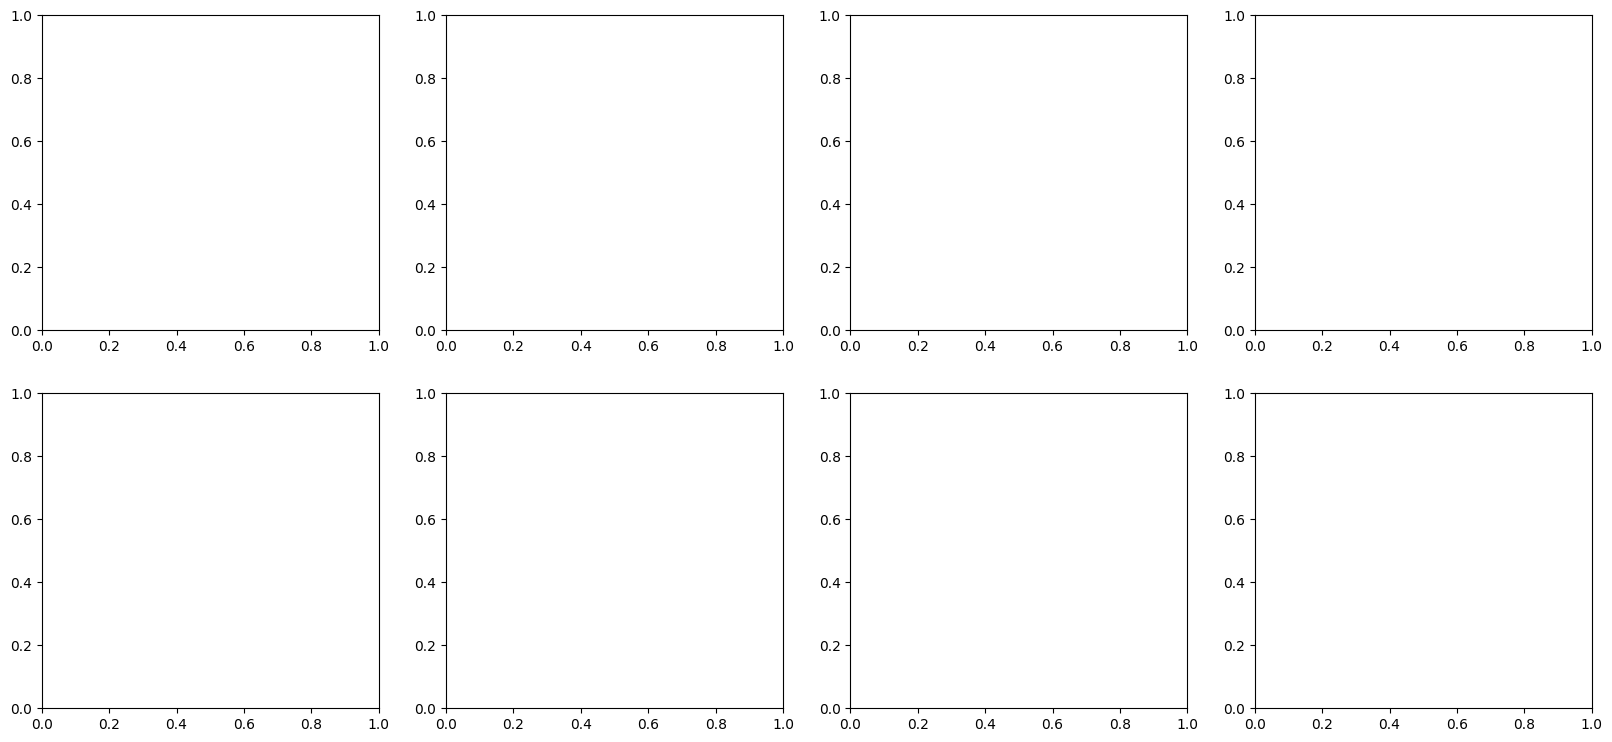

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(42)   # seed biar hasil konsisten
N = 100_000                       # jumlah sampel simulasi
fig, axes = plt.subplots(2, 4, figsize=(20, 9)); axes = axes.ravel()

def ringkas(dist, sampel):        # bandingkan teori vs simulasi
    print(f"E[X]   teori = {dist.mean():.4f} | simulasi = {sampel.mean():.4f}")
    print(f"Var(X) teori = {dist.var():.4f} | simulasi = {sampel.var():.4f}")

def plot_diskrit(ax, dist, sampel, judul, ks):
    emp = np.array([(sampel == k).mean() for k in ks])
    ax.bar(ks - 0.2, dist.pmf(ks), width=0.4, label="PMF teori")
    ax.bar(ks + 0.2, emp, width=0.4, label="Simulasi")
    ax.set_title(judul); ax.legend()

def plot_kontinu(ax, dist, sampel, judul, xs):
    ax.hist(sampel, bins=60, density=True, alpha=0.5, label="Simulasi")
    ax.plot(xs, dist.pdf(xs), lw=2, label="PDF teori")
    ax.set_title(judul); ax.legend()

In [20]:
d = stats.binom(n=20, p=0.1)
print(f"P(X = 2)  = {d.pmf(2):.4f}")
print(f"P(X <= 3) = {d.cdf(3):.4f}")
s = d.rvs(size=N, random_state=rng); ringkas(d, s)
plot_diskrit(axes[0], d, s, "Binomial(20, 0.1): request gagal", np.arange(0, 9))

P(X = 2)  = 0.2852
P(X <= 3) = 0.8670
E[X]   teori = 2.0000 | simulasi = 2.0033
Var(X) teori = 1.8000 | simulasi = 1.7991


In [21]:
d = stats.poisson(mu=4)
print(f"P(X = 6)  = {d.pmf(6):.4f}")
print(f"P(X > 8)  = {d.sf(8):.4f}")
s = d.rvs(size=N, random_state=rng); ringkas(d, s)
plot_diskrit(axes[1], d, s, "Poisson(4): request/detik", np.arange(0, 14))

P(X = 6)  = 0.1042
P(X > 8)  = 0.0214
E[X]   teori = 4.0000 | simulasi = 3.9963
Var(X) teori = 4.0000 | simulasi = 3.9602


In [22]:
d = stats.expon(scale=1000)          # scale = 1/λ = mean
print(f"P(T > 1500)  = {d.sf(1500):.4f}")
print(f"P(T <= 500)  = {d.cdf(500):.4f}")
s = d.rvs(size=N, random_state=rng); ringkas(d, s)
plot_kontinu(axes[5], d, s, "Eksponensial(mean 1000 jam)", np.linspace(0, 5000, 300))

P(T > 1500)  = 0.2231
P(T <= 500)  = 0.3935
E[X]   teori = 1000.0000 | simulasi = 1000.5595
Var(X) teori = 1000000.0000 | simulasi = 995664.3984


In [23]:
d = stats.norm(loc=200, scale=30)
print(f"P(X > 250)        = {d.sf(250):.4f}")
print(f"P(170 < X < 230)  = {d.cdf(230) - d.cdf(170):.4f}")
print(f"Persentil ke-95   = {d.ppf(0.95):.2f} ms")
s = d.rvs(size=N, random_state=rng); ringkas(d, s)
plot_kontinu(axes[6], d, s, "Normal(200, 30): response time (ms)", np.linspace(90, 310, 300))

P(X > 250)        = 0.0478
P(170 < X < 230)  = 0.6827
Persentil ke-95   = 249.35 ms
E[X]   teori = 200.0000 | simulasi = 200.1331
Var(X) teori = 900.0000 | simulasi = 900.9858


In [24]:
d = stats.gamma(a=3, scale=2)        # a = shape (k), scale = θ
print(f"P(T <= 6) = {d.cdf(6):.4f}")
print(f"P(T > 10) = {d.sf(10):.4f}")
s = d.rvs(size=N, random_state=rng); ringkas(d, s)
plot_kontinu(axes[7], d, s, "Gamma(k=3, scale=2): waktu sampai 3 gagal (jam)", np.linspace(0, 25, 300))

P(T <= 6) = 0.5768
P(T > 10) = 0.1247
E[X]   teori = 6.0000 | simulasi = 6.0092
Var(X) teori = 12.0000 | simulasi = 12.0243


Contoh Permasalahan

P(T=20)  manual : 0.036424 | scipy: 0.036424
P(T<=20) manual : 0.595104 | scipy: 0.595104 | simulasi: 0.595200
E[T]   rumus r/p = 20.0000 | scipy: 20.0000 | simulasi: 20.0027
Var[T] rumus r(1-p)/p^2 = 113.3333 | scipy: 113.3333 | simulasi: 113.5150


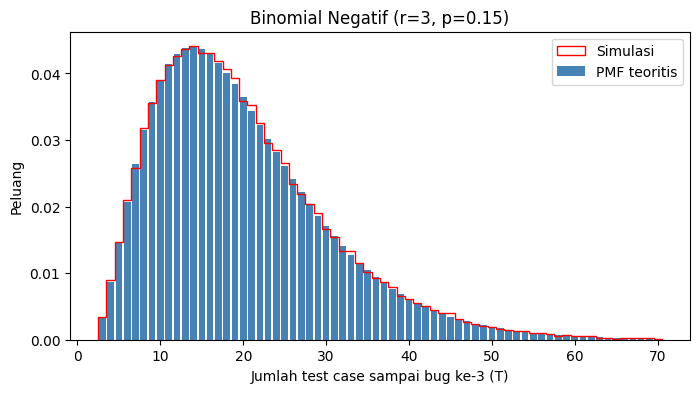

In [25]:
import math
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

p, r = 0.15, 3          # peluang test case menemukan bug, target bug

# --- Manual: P(T=t) = C(t-1, r-1) p^r (1-p)^(t-r)
def pmf_manual(t):
    return math.comb(t-1, r-1) * p**r * (1-p)**(t-r)

p_20_manual = pmf_manual(20)
p_le20_manual = sum(pmf_manual(t) for t in range(r, 21))

# --- SciPy: nbinom menghitung JUMLAH GAGAL sebelum sukses ke-r, jadi T = X + r
nb = stats.nbinom(r, p)
p_20_scipy = nb.pmf(20 - r)
p_le20_scipy = nb.cdf(20 - r)
E_T = nb.mean() + r
Var_T = nb.var()

# --- Simulasi 100.000 percobaan
rng = np.random.default_rng(42)
T_sim = rng.negative_binomial(r, p, 100_000) + r

print(f"P(T=20)  manual : {p_20_manual:.6f} | scipy: {p_20_scipy:.6f}")
print(f"P(T<=20) manual : {p_le20_manual:.6f} | scipy: {p_le20_scipy:.6f} | simulasi: {(T_sim<=20).mean():.6f}")
print(f"E[T]   rumus r/p = {r/p:.4f} | scipy: {E_T:.4f} | simulasi: {T_sim.mean():.4f}")
print(f"Var[T] rumus r(1-p)/p^2 = {r*(1-p)/p**2:.4f} | scipy: {Var_T:.4f} | simulasi: {T_sim.var():.4f}")

t = np.arange(r, 71)
plt.figure(figsize=(8,4))
plt.bar(t, nb.pmf(t - r), color="steelblue", label="PMF teoritis")
plt.hist(T_sim, bins=np.arange(r-0.5, 71.5), density=True, histtype="step", color="red", label="Simulasi")
plt.xlabel("Jumlah test case sampai bug ke-3 (T)"); plt.ylabel("Peluang"); plt.legend()
plt.title("Binomial Negatif (r=3, p=0.15)"); plt.show()

P(Error) = 7/250 = 0.028
  Modul Prior P(M) P(Error|M) Joint P(M n E) Posterior P(M|E)
   Auth     0.4000     0.0200         0.0080           0.2857
Payment     0.3500     0.0500         0.0175           0.6250
 Search     0.2500     0.0100         0.0025           0.0893

Simulasi P(Error)   : 0.02807
Simulasi P(M|Error) : [0.2867 0.6238 0.0895]


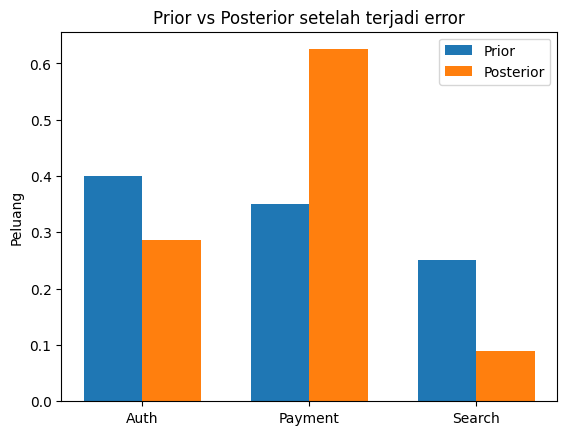

In [26]:
import numpy as np
import pandas as pd
from sympy import Rational
import matplotlib.pyplot as plt

df = pd.DataFrame({
    "Modul": ["Auth", "Payment", "Search"],
    "Prior P(M)": [Rational(40,100), Rational(35,100), Rational(25,100)],
    "P(Error|M)": [Rational(2,100), Rational(5,100), Rational(1,100)],
})
df["Joint P(M n E)"] = df["Prior P(M)"] * df["P(Error|M)"]
p_error = df["Joint P(M n E)"].sum()                  # hukum peluang total
df["Posterior P(M|E)"] = df["Joint P(M n E)"] / p_error

print("P(Error) =", p_error, "=", float(p_error))
out = df.copy()
for c in out.columns[1:]:
    out[c] = out[c].apply(lambda v: f"{float(v):.4f}")
print(out.to_string(index=False))

# Simulasi Monte Carlo
rng = np.random.default_rng(7)
N = 1_000_000
modul = rng.choice(3, size=N, p=[0.40, 0.35, 0.25])
err = rng.random(N) < np.array([0.02, 0.05, 0.01])[modul]
print("\nSimulasi P(Error)   :", round(err.mean(), 5))
print("Simulasi P(M|Error) :", np.round(np.bincount(modul[err], minlength=3)/err.sum(), 4))

x = np.arange(3); w = 0.35
plt.bar(x-w/2, [float(v) for v in df["Prior P(M)"]], w, label="Prior")
plt.bar(x+w/2, [float(v) for v in df["Posterior P(M|E)"]], w, label="Posterior")
plt.xticks(x, df["Modul"]); plt.ylabel("Peluang"); plt.legend()
plt.title("Prior vs Posterior setelah terjadi error"); plt.show()

Baris tiap P berjumlah 1?  True
Distribusi setelah  1 jam: [0.9  0.08 0.02]
Distribusi setelah  3 jam: [0.8172 0.1441 0.0387]
Distribusi setelah 10 jam: [0.7852 0.1683 0.0464]

Stasioner eksak : {a: 135/172, b: 29/172, c: 2/43} -> [0.7849, 0.1686, 0.0465]
Stasioner eigen : [0.7849 0.1686 0.0465]
Stasioner simulasi: [0.7852 0.1682 0.0466]
Availability jangka panjang (tidak Down): 0.9535


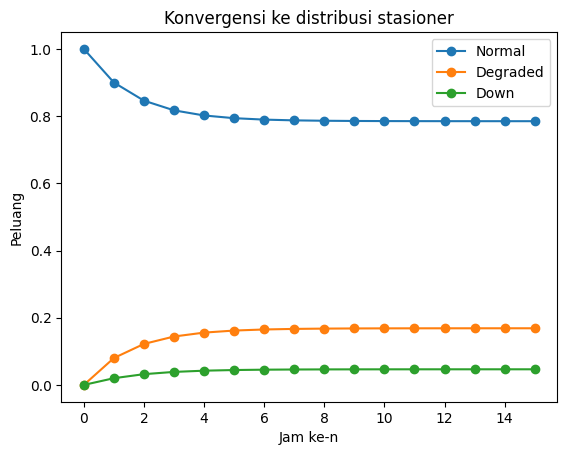

In [27]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt

states = ["Normal", "Degraded", "Down"]
P = np.array([[0.90, 0.08, 0.02],
              [0.30, 0.60, 0.10],
              [0.60, 0.10, 0.30]])
print("Baris tiap P berjumlah 1? ", np.allclose(P.sum(axis=1), 1))

pi0 = np.array([1, 0, 0])                 # mulai dari Normal
for n in (1, 3, 10):
    print(f"Distribusi setelah {n:>2} jam:", np.round(pi0 @ np.linalg.matrix_power(P, n), 4))

# Distribusi stasioner (eksak) dengan SymPy: pi P = pi dan jumlah pi = 1
a, b, c = sp.symbols("a b c")
Ps = sp.Matrix([[sp.Rational(90,100), sp.Rational(8,100), sp.Rational(2,100)],
                [sp.Rational(30,100), sp.Rational(60,100), sp.Rational(10,100)],
                [sp.Rational(60,100), sp.Rational(10,100), sp.Rational(30,100)]])
sol = sp.solve(list((sp.Matrix([[a, b, c]]) * Ps - sp.Matrix([[a, b, c]])).T) + [a+b+c-1], [a, b, c])
print("\nStasioner eksak :", sol, "->", [round(float(sol[v]),4) for v in (a,b,c)])

# Cek dengan eigenvektor
vals, vecs = np.linalg.eig(P.T)
v = np.real(vecs[:, np.argmin(abs(vals-1))]); v = v/v.sum()
print("Stasioner eigen :", np.round(v, 4))

# Simulasi rantai 200.000 jam
rng = np.random.default_rng(1)
s, cnt = 0, np.zeros(3)
for _ in range(200_000):
    s = rng.choice(3, p=P[s]); cnt[s] += 1
print("Stasioner simulasi:", np.round(cnt/cnt.sum(), 4))
print("Availability jangka panjang (tidak Down):", round(1-v[2], 4))

traj = np.array([pi0 @ np.linalg.matrix_power(P, n) for n in range(0, 16)])
for i, nm in enumerate(states): plt.plot(traj[:, i], marker="o", label=nm)
plt.xlabel("Jam ke-n"); plt.ylabel("Peluang"); plt.legend(); plt.title("Konvergensi ke distribusi stasioner"); plt.show()

E[T]=10000  SD[T]=1414.21  z=0.7071
P(T>11000) hampiran Normal : 0.2398
P(T>11000) eksak Gamma     : 0.2322
P(T>11000) simulasi        : 0.2351

Kemencengan (skewness) rata-rata sampel:
  n= 1: skewness=1.976  (teori 2/sqrt(n)=2.000)
  n= 5: skewness=0.879  (teori 2/sqrt(n)=0.894)
  n=30: skewness=0.351  (teori 2/sqrt(n)=0.365)
  n=50: skewness=0.293  (teori 2/sqrt(n)=0.283)


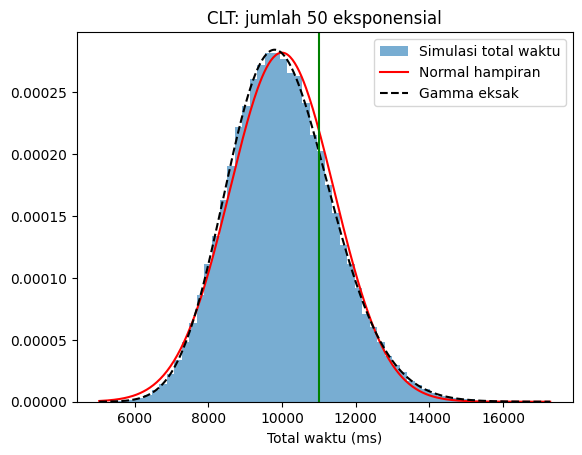

In [28]:
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

mu, n, batas = 200, 50, 11_000          # rata-rata 200 ms, 50 request, batas 11.000 ms
mean_T = n*mu
sd_T = mu*np.sqrt(n)                     # Var(X)=mu^2 untuk eksponensial -> sd total = mu*sqrt(n)
z = (batas-mean_T)/sd_T
p_normal = 1 - stats.norm.cdf(z)
p_exact  = stats.gamma.sf(batas, a=n, scale=mu)   # jumlah n eksponensial = Gamma(n, mu)

rng = np.random.default_rng(3)
T = rng.exponential(mu, size=(100_000, n)).sum(axis=1)
print(f"E[T]={mean_T}  SD[T]={sd_T:.2f}  z={z:.4f}")
print(f"P(T>{batas}) hampiran Normal : {p_normal:.4f}")
print(f"P(T>{batas}) eksak Gamma     : {p_exact:.4f}")
print(f"P(T>{batas}) simulasi        : {(T>batas).mean():.4f}")

print("\nKemencengan (skewness) rata-rata sampel:")
for m in (1, 5, 30, 50):
    s = rng.exponential(mu, size=(50_000, m)).mean(axis=1)
    print(f"  n={m:>2}: skewness={stats.skew(s):.3f}  (teori 2/sqrt(n)={2/np.sqrt(m):.3f})")

plt.hist(T, bins=60, density=True, alpha=.6, label="Simulasi total waktu")
xs = np.linspace(T.min(), T.max(), 400)
plt.plot(xs, stats.norm.pdf(xs, mean_T, sd_T), "r", label="Normal hampiran")
plt.plot(xs, stats.gamma.pdf(xs, n, scale=mu), "k--", label="Gamma eksak")
plt.axvline(batas, color="g"); plt.xlabel("Total waktu (ms)"); plt.legend(); plt.title("CLT: jumlah 50 eksponensial"); plt.show()

Posterior = Beta(32, 78)
Mean prior     : 0.2000
MLE (k/n)      : 0.3000
Mean posterior : 0.2909  (manual 0.2909)
Varians posterior: 0.001858  SD: 0.0431
Interval kredibel 95%: (0.2102, 0.3788)
P(CTR > 0.25 | data) : 0.8271
Simulasi: mean=0.2909, P(CTR>0.25)=0.8265


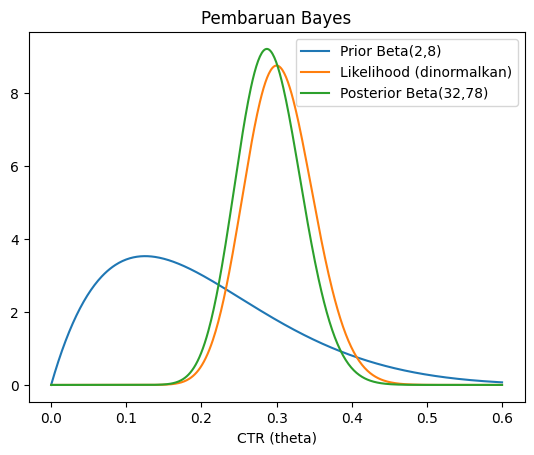

In [29]:
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

a0, b0 = 2, 8            # prior Beta(2,8): keyakinan awal CTR sekitar 20%
n, k = 100, 30           # 100 pengguna, 30 klik
a1, b1 = a0+k, b0+n-k    # konjugat: posterior Beta(a0+k, b0+n-k)

post = stats.beta(a1, b1)
print(f"Posterior = Beta({a1}, {b1})")
print(f"Mean prior     : {a0/(a0+b0):.4f}")
print(f"MLE (k/n)      : {k/n:.4f}")
print(f"Mean posterior : {post.mean():.4f}  (manual {a1/(a1+b1):.4f})")
print(f"Varians posterior: {post.var():.6f}  SD: {post.std():.4f}")
print(f"Interval kredibel 95%: ({post.ppf(0.025):.4f}, {post.ppf(0.975):.4f})")
print(f"P(CTR > 0.25 | data) : {post.sf(0.25):.4f}")

# Cek simulasi
s = np.random.default_rng(5).beta(a1, b1, 200_000)
print(f"Simulasi: mean={s.mean():.4f}, P(CTR>0.25)={(s>0.25).mean():.4f}")

th = np.linspace(0, 0.6, 500)
lik = stats.binom.pmf(k, n, th); lik = lik/(lik.sum()*(th[1]-th[0]))   # likelihood dinormalkan agar sebanding
plt.plot(th, stats.beta.pdf(th, a0, b0), label="Prior Beta(2,8)")
plt.plot(th, lik, label="Likelihood (dinormalkan)")
plt.plot(th, post.pdf(th), label="Posterior Beta(32,78)")
plt.xlabel("CTR (theta)"); plt.legend(); plt.title("Pembaruan Bayes"); plt.show()